# C4 Notebook 02 — Sentinel-1 VV/VH: inventory → one real patch → restartable caching

**FloodRisk Sri Lanka | J26-DS-314 | PP1 retrospective hindcast**

**Data contract:** `COPERNICUS/S1_GRD`, dual polarization **VV/VH**, **IW** mode, latest **quality-accepted acquisition strictly earlier** than simulated **09:00 Asia/Colombo on Day T**. For PP1, maximum acquisition age is **18 days (provisional)**. A fixed gauge-centred **12.8 × 12.8 km** square is constructed by transforming the original private EPSG:4326 point to **EPSG:32644**. Small image exports have a **256 × 256** grid at exactly **50 m output sampling**, and two dB channels. The original Sentinel-1 source is *already calibrated and terrain corrected*. No claim that this is raw SAR or 50 m native resolution.

**Three independently controlled stages:** (1) inventory scenes and quantify possible eligibility **without downloading any imagery**; (2) export and visually inspect **one real patch**, including masks and calibration; (3) explicitly enable study-wide **scene exports** and write a target-free mapping of all 1,429 station-days to cached *unique* scenes. Several days legitimately reuse the same pixels but have **different scene ages**. If no quality-accepted scene exists at or before the cutoff within 18 days, record `MISSING_SAR`, **never substitute later imagery**.

**Important quality distinction:** The inventory only checks metadata and geometric intersection. **Usability is established after exporting actual pixels**. If a newer scene has too many invalid pixels, the selection code automatically tries an older eligible scene within the age limit. Scenes are not treated as independent when reused.

**References:** [Sentinel-1 Earth Engine catalogue](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S1_GRD) · [Earth Engine Sentinel-1 preprocessing](https://developers.google.com/earth-engine/guides/sentinel1) · [small multiband exports](https://developers.google.com/earth-engine/apidocs/ee-image-getdownloadurl).

In [ ]:
# Cell 1 — Imports, paths and EXPLICIT safety switches
from pathlib import Path
from datetime import datetime, timedelta, time as daytime, timezone
from zoneinfo import ZoneInfo
import hashlib, io, json, math, os, re, tempfile, time
import numpy as np
import pandas as pd
from pyproj import Transformer
from shapely.geometry import shape

REPO_ROOT_OVERRIDE = None      # Set only if automatic discovery fails
EE_PROJECT = None             # Set to your Earth Engine project ID if needed
S1_ASSET = 'COPERNICUS/S1_GRD'
SOURCE_VERSION = 'C4_S1_V1_DUALPOL_IW_UTM44_50M_NATIVE_DB_SAMPLE'
MAX_SAR_AGE_DAYS = 18.0       # Provisional; assess inventory before final freeze
MIN_VALID_PIXEL_FRACTION = 0.97  # Provisional threshold, evaluated on actual patch pixels
PILOT_STATION_ID = 'holombuwa'
RUN_STUDY_INVENTORY = True
MAX_NEW_INVENTORIES_PER_RUN = 5
RUN_PATCH_EXPORT = True
MAX_NEW_PATCHES_PER_RUN = 5
STRICT_IMAGE_DB_RANGE = (-60.0, 15.0)  # Gross anomaly check only, no physical clipping
LOCAL_TZ = ZoneInfo('Asia/Colombo')
UTC = timezone.utc
GRID_CRS = 'EPSG:32644'       # WGS84 UTM Zone 44N for all project gauges
PATCH_METERS = 12800.0
GRID_SIZE = 256
PIXEL_METERS = PATCH_METERS / GRID_SIZE
assert PIXEL_METERS == 50


def find_root():
    if REPO_ROOT_OVERRIDE is not None:
        p = Path(REPO_ROOT_OVERRIDE).expanduser().resolve()
        if (p/'c4_fusion').is_dir() and (p/'shared'/'spatial'/'catchments').is_dir(): return p
        raise FileNotFoundError(f'Invalid REPO_ROOT_OVERRIDE: {p}')
    for p0 in [Path.cwd().resolve(), Path.cwd().resolve().parent]:
        for p in [p0, *p0.parents]:
            if (p/'c4_fusion').is_dir() and (p/'shared'/'spatial'/'catchments').is_dir(): return p
    raise FileNotFoundError('Cannot locate J26-DS-314; set REPO_ROOT_OVERRIDE.')

ROOT = find_root()
INDEX_PATH = ROOT/'data/processed/c4/manifests/c4_sample_index_1429.csv'
GAUGE_PATH = ROOT/'c4_fusion/private_data/stations_40_PRIVATE.geojson'
OUT_DIR = ROOT/'data/processed/c4/satellite/sentinel1'
INV_DIR = OUT_DIR/'cache/inventory'
PATCH_DIR = OUT_DIR/'cache/patches'
for d in [OUT_DIR, INV_DIR, PATCH_DIR]: d.mkdir(parents=True,exist_ok=True)
for p in [INDEX_PATH, GAUGE_PATH]:
    if not p.is_file(): raise FileNotFoundError(f'Required local source missing: {p}')


def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def config_hash(d): return hashlib.sha256(json.dumps(d,sort_keys=True).encode()).hexdigest()

def safe_write_bytes(path, payload):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    if path.is_file() and path.read_bytes()==payload: return 'UNCHANGED'
    with tempfile.NamedTemporaryFile(dir=path.parent, prefix='.partial_', delete=False) as tf:
        tf.write(payload); tmp=Path(tf.name)
    os.replace(tmp,path)
    return 'WRITTEN'

def save_json(path, obj):
    return safe_write_bytes(path,(json.dumps(obj,indent=2,sort_keys=True,allow_nan=False)+'\n').encode())

def clean_id(s):
    return re.sub(r'[^a-zA-Z0-9_-]+','_',str(s)).strip('_')

CONFIG = {'source':S1_ASSET,'source_version':SOURCE_VERSION,'max_age_days':MAX_SAR_AGE_DAYS,
          'min_valid_fraction':MIN_VALID_PIXEL_FRACTION,'grid_crs':GRID_CRS,
          'patch_metres':PATCH_METERS,'grid_size':GRID_SIZE,'pixel_metres':PIXEL_METERS,
          'bands':['VV','VH'],'mode':'IW','resample_method':'nearest_native_db'}
CONFIG_HASH=config_hash(CONFIG)
print('ROOT:',ROOT)
print('Private output:',OUT_DIR)
print('Inventory enabled?',RUN_STUDY_INVENTORY,'Bulk patch export enabled?',RUN_PATCH_EXPORT)

In [89]:
# Cell 2 — Strict target-free contract, private registry, metric grid and forecast clocks
sample_index = pd.read_csv(INDEX_PATH,encoding='utf-8-sig',low_memory=False)
required = {'record_id','station_id','forecast_date','split','hindcast_origin_0900_local'}
assert required.issubset(sample_index),f'Missing Notebook 01 columns {required-set(sample_index)}'
assert not {'target_delta_stage_m','target_stage_next_day_m','stage_at_issue_m'} & set(sample_index), 'Target data leaked into image retrieval contract.'
assert len(sample_index)==1429 and sample_index.record_id.is_unique
assert sample_index.station_id.nunique()==39
assert sample_index.split.value_counts().to_dict()=={'TRAIN':809,'VALIDATION':269,'TEST':351}
assert sample_index['forecast_date'].notna().all()
assert (sample_index['record_id']==sample_index['station_id']+'_'+sample_index['forecast_date'].astype(str)).all()

geojson=json.loads(GAUGE_PATH.read_text(encoding='utf-8'))
assert geojson.get('type')=='FeatureCollection' and len(geojson['features'])==40
station_geo={}
for f in geojson['features']:
    sid=f['properties']['station_id']
    xy=f['geometry']['coordinates']
    assert sid not in station_geo and f['geometry']['type']=='Point' and len(xy)==2
    assert 79.0<float(xy[0])<83.0 and 5.0<float(xy[1])<10.0, f'Out-of-region coordinates {sid}'
    station_geo[sid]=(float(xy[0]),float(xy[1]))
assert set(sample_index.station_id).issubset(station_geo)
forward=Transformer.from_crs('EPSG:4326',GRID_CRS,always_xy=True)
reverse=Transformer.from_crs(GRID_CRS,'EPSG:4326',always_xy=True)

def grid_for(sid):
    lon,lat=station_geo[sid]
    x,y=forward.transform(lon,lat)
    left=x-PATCH_METERS/2;top=y+PATCH_METERS/2
    transform=[PIXEL_METERS,0.0,left,0.0,-PIXEL_METERS,top]
    corners_xy=[(left,top),(left+PATCH_METERS,top),(left+PATCH_METERS,top-PATCH_METERS),(left,top-PATCH_METERS)]
    ring=[list(reverse.transform(a,b)) for a,b in corners_xy]
    ring.append(ring[0])
    return transform, ring

def origin_utc(date_str):
    day=datetime.strptime(str(date_str),'%Y-%m-%d').date()
    return datetime.combine(day,daytime(9,0),LOCAL_TZ).astimezone(UTC)

def iso_utc(dt): return dt.astimezone(UTC).isoformat().replace('+00:00','Z')

sample_index['forecast_date']=sample_index.forecast_date.astype(str)
for row in sample_index.itertuples(index=False):
    assert str(row.hindcast_origin_0900_local).startswith(row.forecast_date+' 09:00 ')
assert origin_utc('2025-11-17')==datetime(2025,11,17,3,30,tzinfo=UTC)
start_cutoff=origin_utc(sample_index.forecast_date.min())
end_cutoff=origin_utc(sample_index.forecast_date.max())
SEARCH_START=start_cutoff-timedelta(days=MAX_SAR_AGE_DAYS)
SEARCH_END=end_cutoff+timedelta(seconds=1) # Earth Engine end is exclusive
GAUGE_HASH=sha256(GAUGE_PATH)
INDEX_HASH=sha256(INDEX_PATH)
# Existing weather dataset must refer to the EXACT Notebook 01 retrieval index.
weather_manifest_path=ROOT/'data/processed/c4/weather/c4_weather_manifest_PRIVATE.json'
if weather_manifest_path.is_file():
    weather_manifest=json.loads(weather_manifest_path.read_text(encoding='utf-8'))
    assert weather_manifest.get('target_free_index_sha256')==INDEX_HASH, (
        'Notebook 01 source index differs from the version used by completed ERA5-Land data. '
        'Do not proceed with a different station-day index.')
    print('PASS: Sentinel-1 will use the same target-free index SHA256 as Notebook 04.')
print('PASS: 1,429 target-free forecast records; 39 labelled gauges; separate private 40-gauge registry.')
print('UTC inventory interval:',iso_utc(SEARCH_START),'to',iso_utc(SEARCH_END),'(end exclusive)')
print('First gauge square: 12,800 m each side, on exact 256 × 256 projected grid.')

PASS: Sentinel-1 will use the same target-free index SHA256 as Notebook 04.
PASS: 1,429 target-free forecast records; 39 labelled gauges; separate private 40-gauge registry.
UTC inventory interval: 2025-10-30T03:30:00Z to 2025-12-25T03:30:01Z (end exclusive)
First gauge square: 12,800 m each side, on exact 256 × 256 projected grid.


## Stage A — Query scene **metadata only** (no image downloads)

GEE scene inventory uses the private gauge-centred square to find candidate dual-pol IW acquisitions. A geometric intersection is **not** enough to accept a patch; actual valid-pixel coverage is checked at export. We do not impose one orbit pass because doing so could cause avoidable no-data gaps; the pass and relative orbit are retained to analyze view-angle inconsistency later.

In [90]:
# Cell 3 — Authenticate GEE and declare inventory/candidate-selection helpers
try:
    import ee
except ImportError as exc:
    raise ImportError('Install earthengine-api into this notebook kernel: pip install earthengine-api') from exc
try:
    ee.Initialize(project=EE_PROJECT) if EE_PROJECT else ee.Initialize()
except Exception as exc:
    raise RuntimeError('Earth Engine initialization failed. Authenticate via ee.Authenticate(), and set EE_PROJECT if required.') from exc
print('Earth Engine initialized:',S1_ASSET)


def inventory_path(sid): return INV_DIR/f'{sid}.json'

def read_inventory(sid):
    p=inventory_path(sid)
    if not p.is_file(): return None
    d=json.loads(p.read_text(encoding='utf-8'))
    if d.get('source_config_sha256') != CONFIG_HASH or d.get('private_registry_sha256')!=GAUGE_HASH:
        return None
    return d

def scan_station(sid, force=False):
    old=read_inventory(sid)
    if old is not None and not force: return old,'CACHED'
    _,ring=grid_for(sid)
    footprint=ee.Geometry.Polygon([ring],proj='EPSG:4326',geodesic=False)
    coll=(ee.ImageCollection(S1_ASSET)
        .filterBounds(footprint)
        .filterDate(iso_utc(SEARCH_START),iso_utc(SEARCH_END))
        .filter(ee.Filter.eq('instrumentMode','IW'))
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation','VV'))
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation','VH'))
        .sort('system:time_start'))
    size=int(coll.size().getInfo())
    assert size<=500, f'Unexpected >500 scenes for {sid}; inspect collection query.'
    properties=['system:index','system:time_start','orbitProperties_pass','relativeOrbitNumber_start',
                'orbitNumber_start','platform_number','resolution_meters']
    if size:
        # Earth Engine metadata arrays fetched once; pixel data is never downloaded here.
        items=(coll.toList(size)
               .map(lambda im: ee.Image(im).toDictionary(properties)).getInfo())
    else: items=[]
    scenes=[];seen=set()
    for m in items:
        scene_id=m.get('system:index')
        acq_ms=m.get('system:time_start')
        if not scene_id or acq_ms is None: raise ValueError(f'{sid}: missing mandatory scene ID/time: {m}')
        if scene_id in seen: raise ValueError(f'{sid}: duplicate scene ID {scene_id}')
        seen.add(scene_id)
        t=datetime.fromtimestamp(int(acq_ms)/1000,tz=UTC)
        assert SEARCH_START<=t<SEARCH_END
        scenes.append({'scene_id':str(scene_id),'acquisition_utc':iso_utc(t),
                       'acquisition_epoch_ms':int(acq_ms),
                       'orbit_pass':m.get('orbitProperties_pass'),
                       'relative_orbit':m.get('relativeOrbitNumber_start'),
                       'absolute_orbit':m.get('orbitNumber_start'),
                       'platform':m.get('platform_number'),
                       'native_resolution_m':m.get('resolution_meters')})
    d={'station_id':sid,'source_config_sha256':CONFIG_HASH,'private_registry_sha256':GAUGE_HASH,
       'query_begin_utc':iso_utc(SEARCH_START),'query_end_utc_exclusive':iso_utc(SEARCH_END),
       'scene_count':len(scenes),'scenes':sorted(scenes,key=lambda x:(x['acquisition_epoch_ms'],x['scene_id']))}
    save_json(inventory_path(sid),d)
    return d,'REMOTE_INVENTORY'

def eligible_scenes(sid,forecast_date):
    inv=read_inventory(sid)
    if inv is None: return None  # never treat unqueried station as no-data
    cutoff_ms=int(origin_utc(forecast_date).timestamp()*1000)
    age_ms=MAX_SAR_AGE_DAYS*24*3600*1000
    result=[]
    for s in inv['scenes']:
        diff=cutoff_ms-int(s['acquisition_epoch_ms'])
        if 0<diff<=age_ms:
            result.append({**s,'sar_age_hours':diff/3_600_000.0})
    return sorted(result,key=lambda s:(s['acquisition_epoch_ms'],s['scene_id']),reverse=True)

Earth Engine initialized: COPERNICUS/S1_GRD


In [4]:
# Cell 4 — Real Holombuwa scene inventory; print candidate availability before choosing a patch
pilot_inv,pilot_inv_status=scan_station(PILOT_STATION_ID)
print('Pilot inventory:',PILOT_STATION_ID,pilot_inv_status,'scenes:',pilot_inv['scene_count'])
pi=sample_index.loc[sample_index.station_id==PILOT_STATION_ID].sort_values('forecast_date')
rows=[]
for r in pi.itertuples(index=False):
    choices=eligible_scenes(PILOT_STATION_ID,r.forecast_date)
    rows.append({'record_id':r.record_id,'forecast_date':r.forecast_date,
                 'candidate_scenes':len(choices),'latest_scene':choices[0]['scene_id'] if choices else '',
                 'latest_age_hours':round(choices[0]['sar_age_hours'],2) if choices else np.nan})
pilot_availability=pd.DataFrame(rows)
display(pilot_availability.head(10))
print('Pilot dates with ≥1 metadata-eligible scene:',int(pilot_availability.candidate_scenes.gt(0).sum()),'/',len(pilot_availability))
assert pilot_availability.candidate_scenes.gt(0).any(), ('No VV/VH IW scene in the 18-day window for Holombuwa. '
    'Do not invent coverage; inspect nearby stations or revisit max-age policy explicitly.')

Pilot inventory: holombuwa REMOTE_INVENTORY scenes: 17


,record_id,forecast_date,candidate_scenes,latest_scene,latest_age_hours
0,holombuwa_2025-11-17,2025-11-17,6,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,62.67
1,holombuwa_2025-11-18,2025-11-18,6,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,86.67
2,holombuwa_2025-11-19,2025-11-19,6,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,110.67
3,holombuwa_2025-11-20,2025-11-20,5,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,134.67
4,holombuwa_2025-11-21,2025-11-21,3,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,158.67
5,holombuwa_2025-11-22,2025-11-22,3,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,182.67
6,holombuwa_2025-11-23,2025-11-23,3,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,206.67
7,holombuwa_2025-11-24,2025-11-24,3,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,230.67
8,holombuwa_2025-11-25,2025-11-25,3,S1A_IW_GRDH_1SDV_20251114T124946_20251114T1250...,254.67
9,holombuwa_2025-11-26,2025-11-26,4,S1A_IW_GRDH_1SDV_20251126T002515_20251126T0025...,3.08


Pilot dates with ≥1 metadata-eligible scene: 37 / 37


## Stage B — Export **one real patch** and inspect it before bulk processing

Each raw patch is stored **once per station–Sentinel scene** as a compressed array `[256,256,2]` plus a valid-pixel mask and quality metadata. We deliberately retain **dB pixels**, not scene-level averaged dB statistics. The 50 m grid uses **nearest native-pixel sampling** (Earth Engine default): it is a fixed spatial sampling resolution, *not* a claim of native 50 m sensor pixels or a physically area-weighted mean. An optional future sensitivity test can reduce resolution in **linear radar power** before converting back to dB, but this pilot holds a single, clearly documented method fixed.

`VV`/`VH` out-of-coverage pixels are exported with the `valid` mask, never silently interpreted as zero-water returns. A candidate scene must have at least the provisional `MIN_VALID_PIXEL_FRACTION`, or we try an older candidate within the 18-day limit.

In [92]:
# Cell 5 — Exact-grid scene download and strict pixel QA, with idempotent private caching
import requests
import rasterio
from rasterio.io import MemoryFile
from affine import Affine

NO_DATA=-9999.0

def scene_paths(sid,scene_id):
    stem=f'{clean_id(scene_id)}__{CONFIG_HASH[:12]}'
    dest=PATCH_DIR/sid
    return dest/(stem+'.npz'), dest/(stem+'.json')

def cache_scene_state(sid,scene):
    arr_path,meta_path=scene_paths(sid,scene['scene_id'])
    if not meta_path.is_file(): return None
    m=json.loads(meta_path.read_text(encoding='utf-8'))
    if m.get('source_config_sha256')!=CONFIG_HASH or m.get('private_registry_sha256')!=GAUGE_HASH: return None
    if m.get('quality_status')=='ACCEPTED':
        if not arr_path.is_file() or m.get('patch_sha256')!=sha256(arr_path): return None
        with np.load(arr_path,allow_pickle=False) as dat:
            if dat['sar_db'].shape!=(GRID_SIZE,GRID_SIZE,2) or dat['valid_mask'].shape!=(GRID_SIZE,GRID_SIZE): return None
        return m
    if m.get('quality_status')=='REJECTED_PIXEL_QA': return m
    return None

def ee_scene_tile(sid,scene):
    # Resolve the exact GEE scene by its system:index; never composite adjacent acquisition times.
    image=ee.Image(f"{S1_ASSET}/{scene['scene_id']}")
    vv=image.select('VV');vh=image.select('VH')
    valid=vv.mask().And(vh.mask())
    bands=ee.Image.cat([
        vv.updateMask(valid).unmask(NO_DATA,False).rename('VV'),
        vh.updateMask(valid).unmask(NO_DATA,False).rename('VH'),
        valid.unmask(0,False).rename('valid')
    ]).toFloat()
    transform,_=grid_for(sid)
    url=bands.getDownloadURL({'format':'GEO_TIFF','crs':GRID_CRS,
                              'crs_transform':transform,'dimensions':[GRID_SIZE,GRID_SIZE]})
    response=requests.get(url,timeout=(15,180));response.raise_for_status()
    if len(response.content)>32*1024*1024: raise ValueError('Unexpected oversized patch response')
    with MemoryFile(response.content) as mem:
        with mem.open() as ds:
            if ds.count!=3 or ds.width!=GRID_SIZE or ds.height!=GRID_SIZE:
                raise ValueError(f'Unexpected patch TIFF dimensions/count: {ds.count},{ds.width},{ds.height}')
            if ds.crs is None or ds.crs.to_string()!=GRID_CRS:
                raise ValueError(f'Unexpected projected grid CRS: {ds.crs}')
            expected=Affine(*transform)
            if not np.allclose(tuple(ds.transform)[:6],tuple(expected)[:6],atol=0.02,rtol=0):
                raise ValueError(f'Patch transform does not match 50m gauge-centred export: {ds.transform}')
            values=ds.read().astype(np.float32)
    return values

def quality_check(values):
    pix=np.moveaxis(values[:2],0,-1)
    valid=(values[2]>0.5)&np.isfinite(pix).all(axis=-1)&(pix!=NO_DATA).all(axis=-1)
    coverage=float(valid.mean())
    good=pix[valid]
    basic={'valid_pixel_fraction':coverage,'valid_pixel_count':int(valid.sum()),
           'total_pixel_count':GRID_SIZE**2,'quality_status':None}
    if len(good):
        basic['vv_db_p01_p50_p99']=[float(x) for x in np.percentile(good[:,0],[1,50,99])]
        basic['vh_db_p01_p50_p99']=[float(x) for x in np.percentile(good[:,1],[1,50,99])]
        basic['extreme_db_fraction']=float(((good<STRICT_IMAGE_DB_RANGE[0])|(good>STRICT_IMAGE_DB_RANGE[1])).any(axis=-1).mean())
    else:
        basic['vv_db_p01_p50_p99']=None; basic['vh_db_p01_p50_p99']=None
        basic['extreme_db_fraction']=None
    if coverage<MIN_VALID_PIXEL_FRACTION:
        basic['quality_status']='REJECTED_PIXEL_QA'; basic['reason']='insufficient valid VV+VH image coverage'
    elif basic['extreme_db_fraction'] is not None and basic['extreme_db_fraction']>0.01:
        basic['quality_status']='REJECTED_PIXEL_QA'; basic['reason']='more than 1% of valid pixels outside gross dB sanity range'
    else:
        basic['quality_status']='ACCEPTED';basic['reason']='pass provisional coverage and dB sanity gates'
    return pix,valid,basic

def export_one_scene(sid,scene):
    cached=cache_scene_state(sid,scene)
    if cached is not None: return cached,'CACHE_'+cached['quality_status']
    values=ee_scene_tile(sid,scene) # RETRIEVES ONE new Earth Engine patch
    pix,valid,qa=quality_check(values)
    arr_path,meta_path=scene_paths(sid,scene['scene_id'])
    m={'station_id':sid,'scene':{k:v for k,v in scene.items() if k!='sar_age_hours'},
       'source_config_sha256':CONFIG_HASH,'private_registry_sha256':GAUGE_HASH,
       'grid_crs':GRID_CRS,'grid_transform':grid_for(sid)[0],
       'image_shape':[GRID_SIZE,GRID_SIZE,2],'pixel_metres':PIXEL_METERS,
       'source_units':'dB, Earth Engine terrain-corrected VV/VH','raster_resampling':'nearest native dB',**qa}
    if m['quality_status']=='ACCEPTED':
        buf=io.BytesIO()
        # Invalid pixels remain NaN; valid_mask must be used for training-time filling.
        pix[~valid]=np.nan
        np.savez_compressed(buf,sar_db=pix.astype(np.float32),valid_mask=valid.astype(np.uint8))
        safe_write_bytes(arr_path,buf.getvalue());m['patch_sha256']=sha256(arr_path)
    else: m['patch_sha256']=None
    save_json(meta_path,m)
    return m,'REMOTE_EXPORTED_'+m['quality_status']

In [6]:
# Cell 6 — PILOT: choose an eligible Holombuwa date and export a real scene; fallback if quality rejected
# Pilot uses the latest study date with at least one metadata candidate (easy to change).
choose=pilot_availability.loc[pilot_availability.candidate_scenes.gt(0)].iloc[-1]
PILOT_RECORD_ID=str(choose['record_id'])
pilot_date=str(choose['forecast_date'])
print('Pilot record:',PILOT_RECORD_ID,'forecast origin UTC:',iso_utc(origin_utc(pilot_date)))
pilot_choice=None
for candidate in eligible_scenes(PILOT_STATION_ID,pilot_date):
    meta,status=export_one_scene(PILOT_STATION_ID,candidate)
    print('Scene',candidate['scene_id'],'age',round(candidate['sar_age_hours'],1),'hours,',status,
          'valid pixels:',round(meta['valid_pixel_fraction']*100,2),'%')
    if meta['quality_status']=='ACCEPTED':
        pilot_choice=(candidate,meta)
        break
assert pilot_choice is not None, ('No usable pilot SAR scene within 18 days. Do not manufacture pixels. '
    'Try a different labelled gauge/date or review the explicit scene-age and coverage policies.')
pilot_scene,pilot_metadata=pilot_choice
pilot_array_path,_=scene_paths(PILOT_STATION_ID,pilot_scene['scene_id'])
with np.load(pilot_array_path,allow_pickle=False) as patch:
    PILOT_SAR=patch['sar_db'].copy(); PILOT_VALID=patch['valid_mask'].astype(bool)
assert PILOT_SAR.shape==(256,256,2) and PILOT_VALID.mean()>=MIN_VALID_PIXEL_FRACTION
print('PASS: real VV/VH pilot patch',PILOT_SAR.shape,'age',round(pilot_scene['sar_age_hours'],2),
      'h; coverage',round(PILOT_VALID.mean()*100,2),'%; acquisition strictly BEFORE forecast origin.')
print('VV percentiles:',pilot_metadata['vv_db_p01_p50_p99'])
print('VH percentiles:',pilot_metadata['vh_db_p01_p50_p99'])
print('Scene:',pilot_scene['scene_id'],'pass:',pilot_scene['orbit_pass'],
      'relative orbit:',pilot_scene['relative_orbit'])

Pilot record: holombuwa_2025-12-25 forecast origin UTC: 2025-12-25T03:30:00Z
Scene S1A_IW_GRDH_1SDV_20251220T124942_20251220T125007_062399_07D0F4_44F9 age 110.7 hours, REMOTE_EXPORTED_REJECTED_PIXEL_QA valid pixels: 59.98 %
Scene S1A_IW_GRDH_1SDV_20251220T124913_20251220T124942_062399_07D0F4_1C58 age 110.7 hours, REMOTE_EXPORTED_REJECTED_PIXEL_QA valid pixels: 38.97 %
Scene S1A_IW_GRDH_1SDV_20251220T002512_20251220T002537_062391_07D0AD_947D age 123.1 hours, REMOTE_EXPORTED_ACCEPTED valid pixels: 100.0 %
PASS: real VV/VH pilot patch (256, 256, 2) age 123.08 h; coverage 100.0 %; acquisition strictly BEFORE forecast origin.
VV percentiles: [-12.8754292011261, -7.028103590011597, -0.16574736163019993]
VH percentiles: [-19.709034538269044, -13.981639385223389, -7.785630249977106]
Scene: S1A_IW_GRDH_1SDV_20251220T002512_20251220T002537_062391_07D0AD_947D pass: DESCENDING relative orbit: 19


In [9]:
# Cell 6 — Select a Holombuwa pilot near the flood peak

PILOT_DATE = "2025-11-27"

matches = pilot_availability.loc[
    pilot_availability["forecast_date"].eq(PILOT_DATE)
    & pilot_availability["candidate_scenes"].gt(0)
]

if matches.empty:
    raise ValueError(
        f"No eligible Holombuwa record found for {PILOT_DATE}. "
        "Check pilot_availability for available dates."
    )

choose = matches.iloc[0]
PILOT_RECORD_ID = str(choose["record_id"])
pilot_date=str(choose['forecast_date'])
print('Pilot record:',PILOT_RECORD_ID,'forecast origin UTC:',iso_utc(origin_utc(pilot_date)))
pilot_choice=None
for candidate in eligible_scenes(PILOT_STATION_ID,pilot_date):
    meta,status=export_one_scene(PILOT_STATION_ID,candidate)
    print('Scene',candidate['scene_id'],'age',round(candidate['sar_age_hours'],1),'hours,',status,
          'valid pixels:',round(meta['valid_pixel_fraction']*100,2),'%')
    if meta['quality_status']=='ACCEPTED':
        pilot_choice=(candidate,meta)
        break
assert pilot_choice is not None, ('No usable pilot SAR scene within 18 days. Do not manufacture pixels. '
    'Try a different labelled gauge/date or review the explicit scene-age and coverage policies.')
pilot_scene,pilot_metadata=pilot_choice
pilot_array_path,_=scene_paths(PILOT_STATION_ID,pilot_scene['scene_id'])
with np.load(pilot_array_path,allow_pickle=False) as patch:
    PILOT_SAR=patch['sar_db'].copy(); PILOT_VALID=patch['valid_mask'].astype(bool)
assert PILOT_SAR.shape==(256,256,2) and PILOT_VALID.mean()>=MIN_VALID_PIXEL_FRACTION
print('PASS: real VV/VH pilot patch',PILOT_SAR.shape,'age',round(pilot_scene['sar_age_hours'],2),
      'h; coverage',round(PILOT_VALID.mean()*100,2),'%; acquisition strictly BEFORE forecast origin.')
print('VV percentiles:',pilot_metadata['vv_db_p01_p50_p99'])
print('VH percentiles:',pilot_metadata['vh_db_p01_p50_p99'])
print('Scene:',pilot_scene['scene_id'],'pass:',pilot_scene['orbit_pass'],
      'relative orbit:',pilot_scene['relative_orbit'])

Pilot record: holombuwa_2025-11-27 forecast origin UTC: 2025-11-27T03:30:00Z
Scene S1A_IW_GRDH_1SDV_20251126T124945_20251126T125010_062049_07C34E_7522 age 14.7 hours, REMOTE_EXPORTED_REJECTED_PIXEL_QA valid pixels: 59.84 %
Scene S1A_IW_GRDH_1SDV_20251126T124916_20251126T124945_062049_07C34E_59F5 age 14.7 hours, REMOTE_EXPORTED_REJECTED_PIXEL_QA valid pixels: 39.15 %
Scene S1A_IW_GRDH_1SDV_20251126T002515_20251126T002540_062041_07C2FF_C9CA age 27.1 hours, REMOTE_EXPORTED_ACCEPTED valid pixels: 100.0 %
PASS: real VV/VH pilot patch (256, 256, 2) age 27.08 h; coverage 100.0 %; acquisition strictly BEFORE forecast origin.
VV percentiles: [-13.0260826587677, -7.12312912940979, -0.015118313068522118]
VH percentiles: [-20.11676139831543, -13.743950843811035, -7.2403240442276]
Scene: S1A_IW_GRDH_1SDV_20251126T002515_20251126T002540_062041_07C2FF_C9CA pass: DESCENDING relative orbit: 19


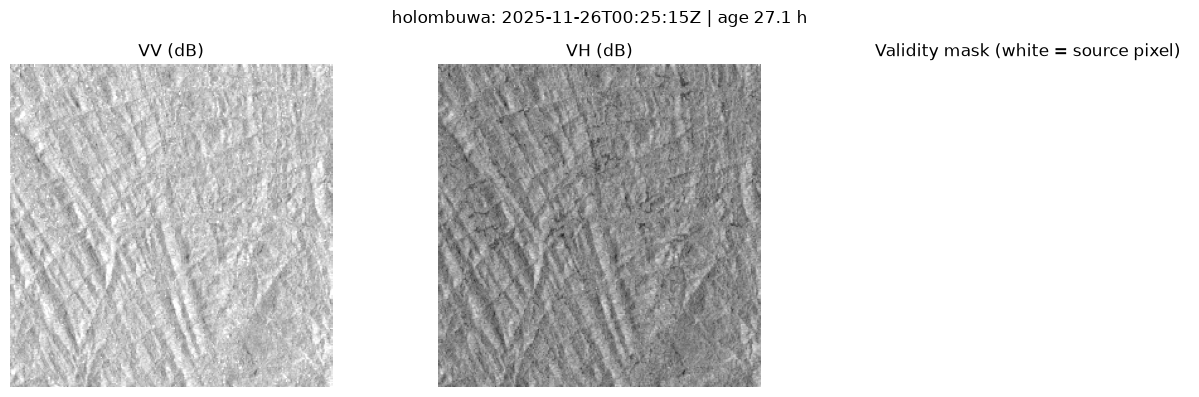

IMPORTANT: visually check striping, no-data borders, scene footprint edges and unusual radio-frequency artefacts.
If clearly defective despite numeric QA, DO NOT proceed; add a documented scene-specific rejection before bulk.


In [10]:
# Cell 7 — Inspect pilot radar image and its invalid-pixel mask (NO training normalization)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,band,label in zip(axes[:2],[0,1],['VV (dB)','VH (dB)']):
    im=np.ma.masked_invalid(PILOT_SAR[:,:,band]);ax.imshow(im,cmap='gray',vmin=-30,vmax=0)
    ax.set_title(label);ax.axis('off')
axes[2].imshow(PILOT_VALID,cmap='gray',vmin=0,vmax=1)
axes[2].set_title('Validity mask (white = source pixel)');axes[2].axis('off')
plt.suptitle(f'{PILOT_STATION_ID}: {pilot_scene["acquisition_utc"]} | age {pilot_scene["sar_age_hours"]:.1f} h')
plt.tight_layout();plt.show()
print('IMPORTANT: visually check striping, no-data borders, scene footprint edges and unusual radio-frequency artefacts.')
print('If clearly defective despite numeric QA, DO NOT proceed; add a documented scene-specific rejection before bulk.')

## Stage C — Controlled, resumable full-study inventory and export

**Do not change the pilot just to improve coverage statistics.** The provisional 18-day rule can be revised *only after inspecting inventory across the 39 gauges*, documenting the new setting and regenerating provenance. Keep `MAX_NEW_INVENTORIES_PER_RUN` and `MAX_NEW_PATCHES_PER_RUN` small until the actual Earth Engine requests are stable. The cache writes one file per **unique station–scene**, not one per forecast date.

In [20]:
# Cell 8 — Inventory every station in small batches, no image pixels downloaded
stations=sorted(sample_index.station_id.unique())
if not RUN_STUDY_INVENTORY:
    print('SKIP: study-wide metadata query is disabled. Set RUN_STUDY_INVENTORY=True in Cell 1 when pilot QA passes.')
else:
    missing=[sid for sid in stations if read_inventory(sid) is None]
    print('Already cached inventories:',len(stations)-len(missing),'/',len(stations),'; next:',missing[:MAX_NEW_INVENTORIES_PER_RUN])
    for sid in missing[:MAX_NEW_INVENTORIES_PER_RUN]:
        d,status=scan_station(sid)
        print(sid,status,'scene records:',d['scene_count'])
    print('Now inventoried:',sum(read_inventory(sid) is not None for sid in stations),'/',len(stations))
    print('RERUN Cell 8 until the result is 39/39; no patch arrays have been downloaded by this step.')

Already cached inventories: 39 / 39 ; next: []
Now inventoried: 39 / 39
RERUN Cell 8 until the result is 39/39; no patch arrays have been downloaded by this step.


In [21]:
# Cell 9 — Metadata-only coverage report across all 1,429 origins (no pixel QA claims)
if all(read_inventory(sid) is not None for sid in stations):
    inv_rows=[]
    for r in sample_index.itertuples(index=False):
        eligible=eligible_scenes(r.station_id,r.forecast_date)
        inv_rows.append({'record_id':r.record_id,'station_id':r.station_id,
                         'forecast_date':r.forecast_date,'split':r.split,
                         'metadata_candidates':len(eligible),
                         'metadata_latest_age_hours':eligible[0]['sar_age_hours'] if eligible else np.nan})
    metadata_coverage=pd.DataFrame(inv_rows)
    print('Metadata-eligible sample count:',int(metadata_coverage.metadata_candidates.gt(0).sum()),'/',len(metadata_coverage))
    print('Samples with no SAR scene within 18 d:',int(metadata_coverage.metadata_candidates.eq(0).sum()))
    display(metadata_coverage.groupby('split').metadata_candidates.agg(['count',lambda x:int((x>0).sum()),'median','max']))
    print('These are only candidate counts; actual image coverage is not guaranteed until patch exports pass QA.')
else:
    print('Complete all 39 inventories in Cell 8 before evaluating source availability.')

Metadata-eligible sample count: 1429 / 1429
Samples with no SAR scene within 18 d: 0


,count,<lambda_0>,median,max
split,,,,
TEST,351,351,4.0,6
TRAIN,809,809,4.0,9
VALIDATION,269,269,6.0,9


These are only candidate counts; actual image coverage is not guaranteed until patch exports pass QA.


In [40]:
# Cell 10 — Determine latest QUALITY-ACCEPTED pre-cutoff scene, allowing fallback to an older valid candidate
# NO extra Earth Engine requests: status is derived entirely from cached inventory and patch metadata.

def resolve_sample(row):
    sid=str(row['station_id']); d=str(row['forecast_date'])
    elig=eligible_scenes(sid,d)
    if elig is None: return {'status':'PENDING_INVENTORY','scene':None,'pending':None}
    if not elig: return {'status':'NO_ELIGIBLE_SCENE','scene':None,'pending':None}
    for s in elig:
        cached=cache_scene_state(sid,s)
        if cached is None:
            return {'status':'PENDING_EXPORT','scene':None,'pending':s}
        if cached['quality_status']=='ACCEPTED':
            return {'status':'AVAILABLE','scene':s,'pending':None,'meta':cached}
    return {'status':'ALL_CANDIDATES_REJECTED','scene':None,'pending':None}


def current_states():
    states=[];pending={}
    for r in sample_index.to_dict('records'):
        z=resolve_sample(r);states.append(z['status'])
        if z['pending'] is not None:
            key=(r['station_id'],z['pending']['scene_id'])
            pending[key]=(r['station_id'],z['pending'])
    return pd.Series(states).value_counts().to_dict(), list(pending.values())

status_counts,pending_scenes=current_states()
print('Current scene selection status:',status_counts)
print('Unique new candidate scene exports needed for next selection pass:',len(pending_scenes))
print('Note: after exporting/rejecting a scene, another older scene may become necessary for some dates.')

Current scene selection status: {'PENDING_EXPORT': 877, 'AVAILABLE': 537, 'ALL_CANDIDATES_REJECTED': 15}
Unique new candidate scene exports needed for next selection pass: 193
Note: after exporting/rejecting a scene, another older scene may become necessary for some dates.


In [85]:
# Cell 11 — Controlled actual scene exports (rerun until no PENDING_EXPORT records remain)
if not RUN_PATCH_EXPORT:
    print('SKIP: RUN_PATCH_EXPORT=False. Complete metadata inventory and visually accept the pilot before turning on.')
elif not all(read_inventory(sid) is not None for sid in stations):
    raise RuntimeError('Complete 39/39 station scene inventories BEFORE bulk patch export.')
else:
    before,queue=current_states()
    print('Starting status:',before,'| new unique scenes attempted in this run:',min(len(queue),MAX_NEW_PATCHES_PER_RUN))
    for sid,scene in queue[:MAX_NEW_PATCHES_PER_RUN]:
        m,s=export_one_scene(sid,scene)
        print(sid,scene['scene_id'],s,'coverage',round(m['valid_pixel_fraction']*100,2),'%')
    after,queue_after=current_states()
    print('Now:',after,'| outstanding unique scene tasks:',len(queue_after))
    print('RERUN Cell 11 while PENDING_EXPORT > 0. Do not call no-data missing until all alternatives checked.')

Starting status: {'AVAILABLE': 1408, 'ALL_CANDIDATES_REJECTED': 21} | new unique scenes attempted in this run: 0
Now: {'AVAILABLE': 1408, 'ALL_CANDIDATES_REJECTED': 21} | outstanding unique scene tasks: 0
RERUN Cell 11 while PENDING_EXPORT > 0. Do not call no-data missing until all alternatives checked.


## Stage D — Verify every sample's observation time and export a *sparse* scene-to-day manifest

A single cached `[256,256,2]` image may be referenced by many `record_id` values. Each row independently stores its **age in hours**, scene identifier, orbit metadata and validity fraction. Do **not** duplicate 1,429 full images on disk. The future model loader will follow each row's `patch_relpath`, use `valid_mask` and training-fold normalization to construct its image tensor.

In [86]:
# Cell 12 — Final quality audit + target-free 1429-row mapping; no GEE calls and no fabricated images
if not all(read_inventory(sid) is not None for sid in stations):
    raise RuntimeError('39/39 metadata inventories must be completed first.')
state_counts,queue=current_states()
if state_counts.get('PENDING_EXPORT',0):
    raise RuntimeError(f"{state_counts['PENDING_EXPORT']} station-days pending a candidate image export; rerun Cell 11.")
if state_counts.get('PENDING_INVENTORY',0): raise RuntimeError('Missing inventory.')
records=[]
for r in sample_index.itertuples(index=False):
    state=resolve_sample({'station_id':r.station_id,'forecast_date':r.forecast_date})
    s=state['scene']; meta=state.get('meta')
    if s is None:
        row={'record_id':r.record_id,'station_id':r.station_id,'forecast_date':r.forecast_date,'split':r.split,
             'sar_available':False,'sar_status':state['status'],
             'sar_scene_id':'','sar_acquisition_utc':'','sar_age_hours':np.nan,'sar_age_logscaled':0.0,
             'sar_validity_flag':0,'sar_valid_pixel_fraction':np.nan,'sar_orbit_pass':'',
             'sar_relative_orbit':np.nan,'patch_relpath':'','patch_sha256':''}
    else:
        age=float(s['sar_age_hours'])
        assert 0<age<=MAX_SAR_AGE_DAYS*24
        assert datetime.fromtimestamp(s['acquisition_epoch_ms']/1000,tz=UTC)<origin_utc(r.forecast_date)
        p,_=scene_paths(r.station_id,s['scene_id'])
        assert p.is_file() and meta['patch_sha256']==sha256(p)
        row={'record_id':r.record_id,'station_id':r.station_id,'forecast_date':r.forecast_date,'split':r.split,
             'sar_available':True,'sar_status':'AVAILABLE',
             'sar_scene_id':s['scene_id'],'sar_acquisition_utc':s['acquisition_utc'],
             'sar_age_hours':age,
             'sar_age_logscaled':float(np.log1p(age/24)/np.log1p(MAX_SAR_AGE_DAYS)),
             'sar_validity_flag':1,'sar_valid_pixel_fraction':meta['valid_pixel_fraction'],
             'sar_orbit_pass':s['orbit_pass'],'sar_relative_orbit':s['relative_orbit'],
             'patch_relpath':p.relative_to(ROOT).as_posix(),'patch_sha256':meta['patch_sha256']}
    records.append(row)
sample_sar=pd.DataFrame(records)
assert len(sample_sar)==1429 and sample_sar.record_id.is_unique
assert sample_sar.record_id.tolist()==sample_index.record_id.tolist()
assert sample_sar.split.value_counts().to_dict()=={'TRAIN':809,'VALIDATION':269,'TEST':351}
assert not {'stage_at_issue_m','target_delta_stage_m','target_stage_next_day_m'} & set(sample_sar)
assert (sample_sar.sar_available==sample_sar.sar_validity_flag.astype(bool)).all()
assert sample_sar.loc[sample_sar.sar_available,'sar_valid_pixel_fraction'].ge(MIN_VALID_PIXEL_FRACTION).all()
print('Source availability AFTER actual-pixel QA:')
display(sample_sar.groupby(['split','sar_status']).size().unstack(fill_value=0))
print('Available station-days:',int(sample_sar.sar_available.sum()),'/',len(sample_sar))
print('Unique accepted station–scene patches:',sample_sar.loc[sample_sar.sar_available,['station_id','sar_scene_id']].drop_duplicates().shape[0])
if sample_sar.sar_available.any():
    print('SAR age hours (available only):')
    display(sample_sar.loc[sample_sar.sar_available,'sar_age_hours'].describe(percentiles=[.05,.5,.95]).to_frame('hours'))
assert not sample_sar.sar_status.str.startswith('PENDING').any()
print('PASS: cutoff, order, splits, sample coverage, age and no-fabrication rules.')

Source availability AFTER actual-pixel QA:


sar_status,ALL_CANDIDATES_REJECTED,AVAILABLE
split,,
TEST,6,345
TRAIN,15,794
VALIDATION,0,269


Available station-days: 1408 / 1429
Unique accepted station–scene patches: 261
SAR age hours (available only):


,hours
count,1408.000000
mean,106.725906
std,77.689508
min,3.072222
5%,3.079444
50%,99.072222
95%,254.678611
max,411.091944


PASS: cutoff, order, splits, sample coverage, age and no-fabrication rules.


In [87]:
# Cell 13 — Save inventory, patch QA, sample mapping and provenance locally (without station coordinates)
inv_flat=[]; qa_flat=[]
for sid in stations:
    inv=read_inventory(sid); assert inv is not None
    for scene in inv['scenes']:
        meta=cache_scene_state(sid,scene)
        inv_flat.append({'station_id':sid,**scene,
                         'patch_qa_status':meta['quality_status'] if meta else 'NOT_REQUIRED_FOR_ANY_SAMPLE'})
        if meta is not None:
            qa_flat.append({'station_id':sid,'scene_id':scene['scene_id'],
                            'acquisition_utc':scene['acquisition_utc'],
                            'quality_status':meta['quality_status'],
                            'valid_pixel_fraction':meta['valid_pixel_fraction'],
                            'extreme_db_fraction':meta['extreme_db_fraction'],
                            'vv_db_p01_p50_p99':str(meta['vv_db_p01_p50_p99']),
                            'vh_db_p01_p50_p99':str(meta['vh_db_p01_p50_p99']),
                            'patch_sha256':meta.get('patch_sha256')})
inv_df=pd.DataFrame(inv_flat)
qa_df=pd.DataFrame(qa_flat)
outputs={
    'c4_s1_scene_inventory_39_PRIVATE.csv':inv_df.to_csv(index=False).encode('utf-8'),
    'c4_s1_patch_QA_PRIVATE.csv':qa_df.to_csv(index=False).encode('utf-8'),
    'c4_s1_sample_index_1429_PRIVATE.csv':sample_sar.to_csv(index=False).encode('utf-8'),
}
for name,data in outputs.items():
    print(name,safe_write_bytes(OUT_DIR/name,data))
manifest={'source_version':SOURCE_VERSION,'asset':S1_ASSET,'feature_contract':'VV/VH dB image [256,256,2] + separate valid mask + age hours + availability flag',
 'mode':'IW dual-VV-VH','grid_crs':GRID_CRS,'grid_size':GRID_SIZE,
 'pixel_metres':PIXEL_METERS,'patch_extent_metres':PATCH_METERS,
 'reprojection':'source dB nearest-pixel 50m sampling; NOT linear-power area averaging',
 'source_config':CONFIG,'source_config_sha256':CONFIG_HASH,
 'private_station_registry_sha256':GAUGE_HASH,'notebook01_target_free_index_sha256':INDEX_HASH,
 'forecast_origin':'Day T 09:00 Asia/Colombo; all source acquisitions strictly earlier',
 'max_age_days_provisional':MAX_SAR_AGE_DAYS,'min_valid_pixel_fraction_provisional':MIN_VALID_PIXEL_FRACTION,
 'n_labelled_station_days':len(sample_sar),'n_labelled_gauges':len(stations),
 'n_available_station_days':int(sample_sar.sar_available.sum()),
 'n_unique_accepted_patches':int(sample_sar.loc[sample_sar.sar_available,['station_id','sar_scene_id']].drop_duplicates().shape[0]),
 'output_sha256':{name:sha256(OUT_DIR/name) for name in outputs},
 'limitations':['Metadata inventory intersection is not pixel-valid coverage',
                '50m output sampling is not native sensor resolution',
                'This is a retrospective hindcast; publication latency unverified',
                'Radar orbit changes affect look geometry; pass and orbit retained for sensitivity QA',
                'Provisional 18-day staleness and 97% image coverage policy',
                'A scene reused on several forecast dates is NOT a new independent image']}
print('c4_s1_manifest_PRIVATE.json',save_json(OUT_DIR/'c4_s1_manifest_PRIVATE.json',manifest))
print('PASS: Private cache and 1,429-row scene-to-date manifest written. All datasets remain in ignored local data/processed/.')

c4_s1_scene_inventory_39_PRIVATE.csv WRITTEN
c4_s1_patch_QA_PRIVATE.csv WRITTEN
c4_s1_sample_index_1429_PRIVATE.csv WRITTEN
c4_s1_manifest_PRIVATE.json WRITTEN
PASS: Private cache and 1,429-row scene-to-date manifest written. All datasets remain in ignored local data/processed/.


## Stage E — Glencourse ONLY: same-pass slice mosaics (append-only recovery experiment)

**Why this section exists.** The original 1,429-row mapping has 21 unavailable Glencourse rows, but Glencourse inventory identifies adjacent **Sentinel-1A IW VV/VH slices from the same orbit** covering approximately 60% and 40% of its 12.8-km patch. Three candidate passes are **2025-11-14, 2025-11-26 and 2025-12-20**. **The union coverage has not yet been tested.** This section measures it from exported pixels: adjacent scene intersection *alone* is not evidence of valid coverage.

**Run only existing code cells labelled Cell 1, Cell 2, Cell 3 and Cell 5, in that order**, then run Glencourse cells **G1–G6**. Review the QA plots and only then run **G7**. DO NOT rerun Cell 4, either Cell 6, Cell 7, or Cells 8–13. (The existing Cell 3 initializes Earth Engine; Cell 5 only defines helpers.)

**Safety contract:** source filenames from Stage D remain untouched. We preserve all existing 1,408 available rows, their scene IDs, paths and hashes; we update *only* the original 21 Glencourse-missing rows in a **new** 1,429-row CSV under `sentinel1/glencourse_mosaic_extension/`. Original source imagery is never silently replaced. Any mosaic below **strictly >97% valid VV+VH pixels**, or failing existing gross dB QA, stays unavailable. Two source scene IDs, true acquisition times, union and overlap mask fractions remain auditable in separate sidecars. The mosaic is a **single-orbit slice join**, not a temporal multi-day composite; the older of the two timestamps is used for conservative age calculation. Earth Engine reports reflect pixel-data access, not operational product publication latency.

No existing full-study inventory or patch-export cell is necessary here. A mosaic accepted here is one patch reused by eligible forecast days, **not 9/6/6 independent satellite observations**.

In [93]:
# G1 — Load and lock ORIGINAL artifacts; zero EE queries, no output writes
GLEN_ID = 'glencourse'
GLEN_SOURCE_MANIFEST = OUT_DIR/'c4_s1_manifest_PRIVATE.json'
GLEN_SOURCE_INDEX = OUT_DIR/'c4_s1_sample_index_1429_PRIVATE.csv'
GLEN_SOURCE_INV = OUT_DIR/'c4_s1_scene_inventory_39_PRIVATE.csv'
GLEN_SOURCE_QA = OUT_DIR/'c4_s1_patch_QA_PRIVATE.csv'
GLEN_ORIGINALS = [GLEN_SOURCE_INDEX, GLEN_SOURCE_INV, GLEN_SOURCE_QA]
for path in [GLEN_SOURCE_MANIFEST, *GLEN_ORIGINALS]:
    if not path.is_file():
        raise FileNotFoundError(f'Need the original Notebook 02 artifact in the project: {path}')

glen_source_manifest = json.loads(GLEN_SOURCE_MANIFEST.read_text(encoding='utf-8'))
assert glen_source_manifest['source_config_sha256'] == CONFIG_HASH, 'Original configuration changed; do not regenerate it.'
assert glen_source_manifest['private_station_registry_sha256'] == GAUGE_HASH
assert glen_source_manifest['notebook01_target_free_index_sha256'] == INDEX_HASH
GLEN_BASE_HASHES = {p.name: sha256(p) for p in [GLEN_SOURCE_MANIFEST, *GLEN_ORIGINALS]}
for path in GLEN_ORIGINALS:
    assert GLEN_BASE_HASHES[path.name] == glen_source_manifest['output_sha256'][path.name], (path.name, 'original hash mismatch')

glen_base = pd.read_csv(GLEN_SOURCE_INDEX, low_memory=False)
glen_inv = pd.read_csv(GLEN_SOURCE_INV, low_memory=False)
glen_qa = pd.read_csv(GLEN_SOURCE_QA, low_memory=False)
assert len(glen_base) == 1429 and glen_base.record_id.is_unique
assert glen_base.record_id.astype(str).tolist() == sample_index.record_id.astype(str).tolist(), 'Notebook 01 row order changed.'
assert glen_base.sar_available.sum() == 1408
G_MISSING = glen_base.loc[~glen_base.sar_available].copy()
assert len(G_MISSING) == 21 and set(G_MISSING.station_id) == {GLEN_ID}, 'The source 21-gap baseline is not the expected one.'
assert len(glen_inv.query('station_id == @GLEN_ID')) == 17
print('LOCKED:', len(glen_base), 'rows,', int(glen_base.sar_available.sum()), 'existing available,', len(G_MISSING), 'Glencourse missing.')
print('Original files are read only; extensions will use distinct output paths.')
print('Missing date windows:', G_MISSING.forecast_date.min(), 'to', G_MISSING.forecast_date.max())

LOCKED: 1429 rows, 1408 existing available, 21 Glencourse missing.
Original files are read only; extensions will use distinct output paths.
Missing date windows: 2025-11-17 to 2025-12-25


In [94]:
# G2 — Build conservative same-pass/same-orbit adjacent pairs and map ONLY the 21 missing dates
# Scene metadata and previously measured individual coverages are reused; NO EE request here.
glen_scenes = (glen_inv.loc[glen_inv.station_id.eq(GLEN_ID)].copy()
               .merge(glen_qa.loc[glen_qa.station_id.eq(GLEN_ID),
                                 ['scene_id','quality_status','valid_pixel_fraction']],
                      on='scene_id',how='left',validate='one_to_one'))
assert len(glen_scenes) == 17 and glen_scenes.quality_status.notna().all()
glen_scenes['acq'] = pd.to_datetime(glen_scenes.acquisition_utc, utc=True)
glen_scenes['acq_day'] = glen_scenes.acq.dt.strftime('%Y%m%d')

GLEN_PAIR_BY_ID = {}
keys = ['acq_day','platform','absolute_orbit','relative_orbit','orbit_pass']
for group_key, group in glen_scenes.groupby(keys,dropna=False):
    group = group.sort_values(['acq','scene_id'])
    # Only exactly TWO consecutive slices within 90s from the SAME platform and orbit.
    if len(group) != 2 or group.orbit_pass.iloc[0] != 'DESCENDING':
        continue
    a,b = group.iloc[0],group.iloc[1]
    gap_s = (b.acq-a.acq).total_seconds()
    if not (0 < gap_s <= 90):
        continue
    if any(group.quality_status.ne('REJECTED_PIXEL_QA')):
        continue
    mid = f'GLEN_S1_{group_key[0]}_ABS{int(group_key[2])}'
    GLEN_PAIR_BY_ID[mid] = {
        'mosaic_id':mid, 'scene_ids':[str(a.scene_id),str(b.scene_id)],
        'source_utc':[str(a.acquisition_utc),str(b.acquisition_utc)],
        'source_individual_valid_fractions':[float(a.valid_pixel_fraction),float(b.valid_pixel_fraction)],
        'acq_earliest_utc':str(a.acquisition_utc), 'acq_latest_utc':str(b.acquisition_utc),
        'platform':str(group_key[1]), 'orbit_pass':str(group_key[4]),
        'absolute_orbit':int(group_key[2]),'relative_orbit':int(group_key[3]),
        'time_gap_seconds':gap_s
    }

GLEN_SELECTION = {}  # record_id -> mosaic ID; never extends beyond the original missing rows
for row in G_MISSING.itertuples(index=False):
    cutoff = origin_utc(str(row.forecast_date))
    eligible = []
    for m in GLEN_PAIR_BY_ID.values():
        earlier = datetime.fromisoformat(m['acq_earliest_utc'].replace('Z','+00:00'))
        later = datetime.fromisoformat(m['acq_latest_utc'].replace('Z','+00:00'))
        age_h = (cutoff-earlier).total_seconds()/3600.0
        if later < cutoff and 0 < age_h <= MAX_SAR_AGE_DAYS*24:
            eligible.append(m)
    if not eligible:
        raise RuntimeError(f'No eligible strict same-orbit pair for {row.record_id}; leave original MISSING_SAR.')
    selected = max(eligible,key=lambda m:m['acq_latest_utc'])
    GLEN_SELECTION[str(row.record_id)] = selected['mosaic_id']

GLEN_REQUIRED_IDS = sorted(set(GLEN_SELECTION.values()))
GLEN_PLAN = pd.DataFrame([
    {'mosaic_id':mid,'source_start_utc':GLEN_PAIR_BY_ID[mid]['acq_earliest_utc'],
     'slice_1_fraction':GLEN_PAIR_BY_ID[mid]['source_individual_valid_fractions'][0],
     'slice_2_fraction':GLEN_PAIR_BY_ID[mid]['source_individual_valid_fractions'][1],
     'missing_station_days':sum(v==mid for v in GLEN_SELECTION.values())}
    for mid in GLEN_REQUIRED_IDS
])
assert len(GLEN_SELECTION) == 21 and len(GLEN_REQUIRED_IDS) == 3
assert sorted(GLEN_PLAN.missing_station_days.tolist()) == [6,6,9]
assert set(pd.to_datetime(GLEN_PLAN.source_start_utc).dt.strftime('%Y-%m-%d')) == {'2025-11-14','2025-11-26','2025-12-20'}
display(GLEN_PLAN)
print('This is a candidate plan only; coverage of the MASK UNION is not known until G4 runs.')

,mosaic_id,source_start_utc,slice_1_fraction,slice_2_fraction,missing_station_days
0,GLEN_S1_20251114_ABS61866,2025-11-14T00:25:15Z,0.598328,0.403702,9
1,GLEN_S1_20251126_ABS62041,2025-11-26T00:25:15Z,0.599716,0.402374,6
2,GLEN_S1_20251220_ABS62391,2025-12-20T00:25:12Z,0.600281,0.401810,6


This is a candidate plan only; coverage of the MASK UNION is not known until G4 runs.


In [95]:
# G3 — Define SINGLE-ORBIT Glencourse-only mosaic reader & private cache; no EE requests yet
GLEN_VERSION = 'C4_S1_GLENC_SAME_PASS_SLICE_MOSAIC_V1'
GLEN_MOSAIC_CFG = {'version':GLEN_VERSION, 'parent_config_hash':CONFIG_HASH,
                   'min_valid_pixel_fraction_strictly_above':MIN_VALID_PIXEL_FRACTION,
                   'join_rule':'same satellite/pass/relative+absolute orbit; two adjacent slices <=90s',
                   'age_rule':'oldest source scene; both strictly earlier than cutoff',
                   'mosaic_priority':'later slice wins only in any overlap; masked pixel union'}
GLEN_MOSAIC_HASH = config_hash(GLEN_MOSAIC_CFG)
GLEN_CACHE = PATCH_DIR/GLEN_ID/'mosaics'
GLEN_OUTPUT = OUT_DIR/'glencourse_mosaic_extension'
GLEN_CACHE.mkdir(parents=True,exist_ok=True)
GLEN_MAX_NEW_MOSAICS_PER_RUN = 3  # at most THREE 256x256 remote downloads


def glen_paths(m):
    stem = m['mosaic_id']+'__'+GLEN_MOSAIC_HASH[:12]
    return GLEN_CACHE/(stem+'.npz'), GLEN_CACHE/(stem+'.json')


def glen_cached(m):
    arr,meta_path = glen_paths(m)
    if not meta_path.is_file():
        return None
    meta = json.loads(meta_path.read_text(encoding='utf-8'))
    if meta.get('mosaic_config_sha256') != GLEN_MOSAIC_HASH or meta.get('source_scene_ids') != m['scene_ids']:
        raise RuntimeError(f'Stale or modified Glencourse mosaic metadata: {meta_path}')
    if meta['quality_status'] == 'ACCEPTED':
        if not arr.is_file() or sha256(arr) != meta.get('patch_sha256'):
            raise RuntimeError(f'Missing/corrupted accepted mosaic: {arr}')
        with np.load(arr,allow_pickle=False) as data:
            assert data['sar_db'].shape == (GRID_SIZE,GRID_SIZE,2)
            assert data['valid_mask'].shape == (GRID_SIZE,GRID_SIZE)
    return meta


def glen_download_pair(m):
    # Homogeneous slices: force joint VV+VH validity on EACH scene BEFORE mosaicking.
    # Do not mosaic separate dates, ascending+descending passes, or different orbits.
    imgs=[]; scene_masks=[]
    for scene_id in m['scene_ids']:
        original = ee.Image(f'{S1_ASSET}/{scene_id}')
        dual = original.select(['VV','VH'])
        together = dual.select('VV').mask().And(dual.select('VH').mask())
        imgs.append(dual.updateMask(together))
        scene_masks.append(together.unmask(0,False).rename('count'))
    mosaicked = ee.ImageCollection.fromImages(imgs).mosaic()
    union_mask = mosaicked.select('VV').mask().And(mosaicked.select('VH').mask())
    count = ee.ImageCollection.fromImages(scene_masks).sum().rename('source_count')
    bundle = ee.Image.cat([
        mosaicked.select('VV').unmask(NO_DATA,False).rename('VV'),
        mosaicked.select('VH').unmask(NO_DATA,False).rename('VH'),
        union_mask.unmask(0,False).rename('valid'),
        count.unmask(0,False)
    ]).toFloat()
    transform,_ = grid_for(GLEN_ID)
    url = bundle.getDownloadURL({'format':'GEO_TIFF','crs':GRID_CRS,
                                 'crs_transform':transform,'dimensions':[GRID_SIZE,GRID_SIZE]})
    response = requests.get(url,timeout=(15,180))
    response.raise_for_status()
    if len(response.content) > 32*1024*1024:
        raise RuntimeError('Unexpected >32MB Glencourse mosaic payload')
    with MemoryFile(response.content) as mem:
        with mem.open() as ds:
            if ds.count != 4 or ds.width != GRID_SIZE or ds.height != GRID_SIZE:
                raise RuntimeError(f'Bad mosaic GeoTIFF shape: {ds.count,ds.height,ds.width}')
            if ds.crs is None or ds.crs.to_string() != GRID_CRS:
                raise RuntimeError(f'Bad mosaic CRS: {ds.crs}')
            if not np.allclose(tuple(ds.transform)[:6],tuple(Affine(*transform))[:6],atol=.02,rtol=0):
                raise RuntimeError(f'Bad mosaic grid transform: {ds.transform}')
            raw=ds.read().astype(np.float32)
    v=(raw[2]>0.5)
    n=raw[3]
    if not np.isfinite(n).all() or not np.isclose(n,np.rint(n),atol=.001).all():
        raise RuntimeError('Invalid source-count band; review mosaic mask logic')
    if not np.array_equal(v,n>0.5):
        raise RuntimeError('Composite valid band disagrees with union of input scene masks')
    pix,valid,qa = quality_check(raw[:3])
    diagnostics={'valid_union_fraction':float(valid.mean()),
                 'source_overlap_fraction':float((n>1.5).mean()),
                 'source_1_or_2_fraction':float((n>0.5).mean()),
                 'source_gap_fraction':float((n<0.5).mean())}
    return pix,valid,qa,diagnostics


def glen_export_pair(m):
    prior=glen_cached(m)
    if prior is not None: return prior,'CACHED'
    pix,valid,qa,stats = glen_download_pair(m)  # ONE remote request for this pair
    # User-requested >97%, stronger than the original >=97% threshold.
    if qa['quality_status']=='ACCEPTED' and not qa['valid_pixel_fraction'] > MIN_VALID_PIXEL_FRACTION:
        qa['quality_status']='REJECTED_PIXEL_QA'
        qa['reason']='mosaic coverage not STRICTLY above 97%'
    a,b=glen_paths(m)
    meta={**m,'station_id':GLEN_ID,'source_scene_ids':m['scene_ids'],
          'source_config_sha256':CONFIG_HASH,'mosaic_config_sha256':GLEN_MOSAIC_HASH,
          'private_registry_sha256':GAUGE_HASH,'grid_crs':GRID_CRS,
          'grid_transform':grid_for(GLEN_ID)[0], 'pixel_metres':PIXEL_METERS,
          'bands':['VV','VH'],'units':'Earth Engine terrain-corrected dB',
          'mosaic_is_consecutive_slices_not_different_dates':True,
          **qa,**stats,'patch_sha256':None}
    if qa['quality_status']=='ACCEPTED':
        pix[~valid]=np.nan
        buf=io.BytesIO()
        np.savez_compressed(buf,sar_db=pix.astype(np.float32),valid_mask=valid.astype(np.uint8))
        safe_write_bytes(a,buf.getvalue())
        meta['patch_sha256']=sha256(a)
    save_json(b,meta)
    return meta,'REMOTE_'+meta['quality_status']
print('Mosaic helper definitions loaded; original scene caches are untouched.')

Mosaic helper definitions loaded; original scene caches are untouched.


In [96]:
# G4 — THE ONLY NEW EE DOWNLOAD STAGE: export/reuse up to THREE required mosaics
# Idempotent: rerunning this cell only requests pairs without cached QA metadata.
for mid in GLEN_REQUIRED_IDS[:]:
    m=GLEN_PAIR_BY_ID[mid]
    prior=glen_cached(m)
    if prior is not None:
        print('CACHE:',mid,'status=',prior['quality_status'],
              'valid=',round(100*prior['valid_pixel_fraction'],3),'%')

pending=[GLEN_PAIR_BY_ID[mid] for mid in GLEN_REQUIRED_IDS if glen_cached(GLEN_PAIR_BY_ID[mid]) is None]
print('Unique new downloads required:',len(pending),'| bounded this run:',min(len(pending),GLEN_MAX_NEW_MOSAICS_PER_RUN))
for m in pending[:GLEN_MAX_NEW_MOSAICS_PER_RUN]:
    meta,state=glen_export_pair(m)
    print(state,m['mosaic_id'],'valid union=',round(meta['valid_pixel_fraction']*100,3),'%',
          'overlap=',round(meta['source_overlap_fraction']*100,3),'%',
          'strictly >97% accepted?',meta['quality_status']=='ACCEPTED')
remaining=sum(glen_cached(GLEN_PAIR_BY_ID[mid]) is None for mid in GLEN_REQUIRED_IDS)
print('Pairs remaining:',remaining)
if remaining:
    print('Rerun ONLY G4 after resolving any network error. Do not rerun study-wide exports.')

Unique new downloads required: 3 | bounded this run: 3
REMOTE_ACCEPTED GLEN_S1_20251114_ABS61866 valid union= 99.992 % overlap= 0.211 % strictly >97% accepted? True
REMOTE_ACCEPTED GLEN_S1_20251126_ABS62041 valid union= 99.991 % overlap= 0.218 % strictly >97% accepted? True
REMOTE_ACCEPTED GLEN_S1_20251220_ABS62391 valid union= 99.994 % overlap= 0.215 % strictly >97% accepted? True
Pairs remaining: 0


GLEN_S1_20251114_ABS61866
  | coverage=
  99.9924
  %
  | overlap=
  0.2106
  %
  | status=
  ACCEPTED
  | source IDs:
  S1A_IW_GRDH_1SDV_20251114T002515_20251114T002540_061866_07BC30_55DA
  S1A_IW_GRDH_1SDV_20251114T002540_20251114T002606_061866_07BC30_484A


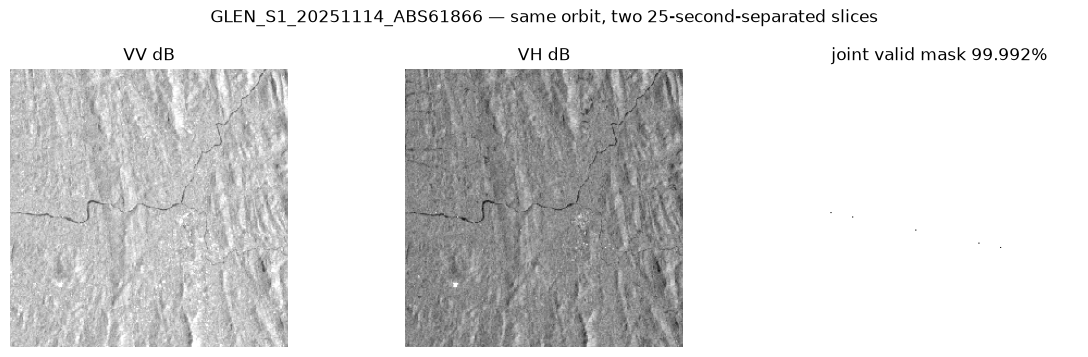

GLEN_S1_20251126_ABS62041
  | coverage=
  99.9908
  %
  | overlap=
  0.2182
  %
  | status=
  ACCEPTED
  | source IDs:
  S1A_IW_GRDH_1SDV_20251126T002515_20251126T002540_062041_07C2FF_C9CA
  S1A_IW_GRDH_1SDV_20251126T002540_20251126T002605_062041_07C2FF_436D


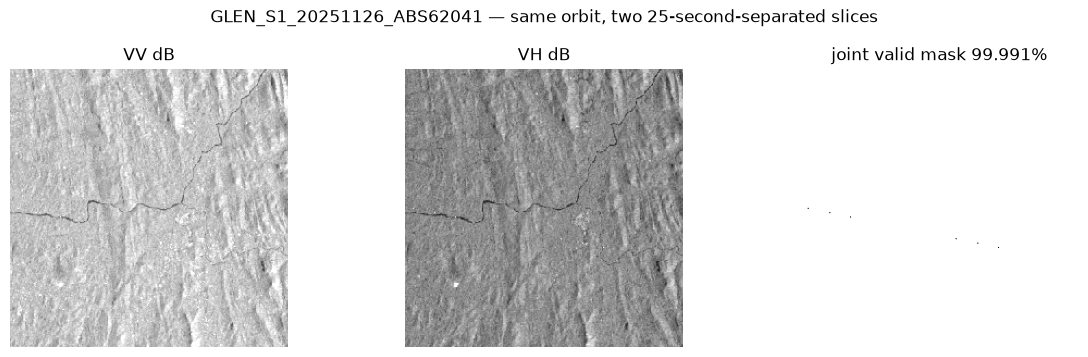

GLEN_S1_20251220_ABS62391
  | coverage=
  99.9939
  %
  | overlap=
  0.2151
  %
  | status=
  ACCEPTED
  | source IDs:
  S1A_IW_GRDH_1SDV_20251220T002512_20251220T002537_062391_07D0AD_947D
  S1A_IW_GRDH_1SDV_20251220T002537_20251220T002603_062391_07D0AD_0184


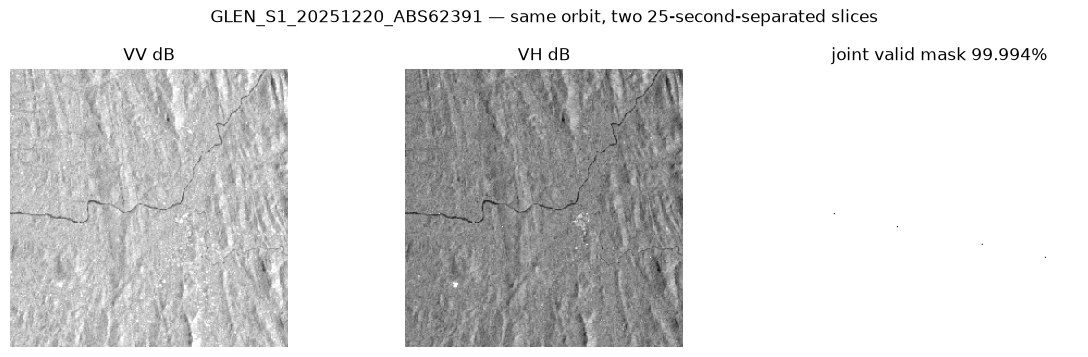

Accepted mosaics plotted: 3 of 3
Inspect for seam stripes or orbit-dependent artefacts before approving G7.


In [97]:
# G5 — Local QA images + no remote requests; inspect mosaicked VV, VH and valid mask
import matplotlib.pyplot as plt
shown=0
for mid in GLEN_REQUIRED_IDS:
    m=GLEN_PAIR_BY_ID[mid]
    meta=glen_cached(m)
    if meta is None:
        print('NOT YET TESTED:',mid)
        continue
    print(mid,'| coverage=',round(100*meta['valid_pixel_fraction'],4),'%',
          '| overlap=',round(100*meta['source_overlap_fraction'],4),'%',
          '| status=',meta['quality_status'],'| source IDs:',*meta['source_scene_ids'],sep='\n  ')
    if meta['quality_status'] != 'ACCEPTED':
        print('REJECTED: not saved as image; do not assign this pair to station-days.')
        continue
    arr,_=glen_paths(m)
    with np.load(arr,allow_pickle=False) as data:
        sar=data['sar_db'].copy()
        mask=data['valid_mask'].astype(bool)
    fig,axes=plt.subplots(1,3,figsize=(12,3.6))
    for b,ax in enumerate(axes[:2]):
        ax.imshow(np.ma.masked_invalid(sar[:,:,b]),cmap='gray',vmin=-30,vmax=0)
        ax.set_title(['VV dB','VH dB'][b]);ax.axis('off')
    axes[2].imshow(mask,cmap='gray',vmin=0,vmax=1)
    axes[2].set_title(f'joint valid mask {100*mask.mean():.3f}%');axes[2].axis('off')
    fig.suptitle(mid+' — same orbit, two 25-second-separated slices')
    plt.tight_layout();plt.show()
    shown+=1
print('Accepted mosaics plotted:',shown,'of',len(GLEN_REQUIRED_IDS))
print('Inspect for seam stripes or orbit-dependent artefacts before approving G7.')

In [98]:
# G6 — Construct an IN-MEMORY 1429-row ALTERNATIVE mapping (no writes, no EE)
# Only the 21 baseline-missing Glencourse rows may change. All other rows remain identical.
not_tested=[mid for mid in GLEN_REQUIRED_IDS if glen_cached(GLEN_PAIR_BY_ID[mid]) is None]
if not_tested:
    raise RuntimeError(f'Test all required pairs in G4 first; not tested: {not_tested}')

glen_merged=glen_base.copy(deep=True)
glen_recovery=[]
for ix,row in glen_base.loc[~glen_base.sar_available].iterrows():
    mid=GLEN_SELECTION[str(row.record_id)]
    m=GLEN_PAIR_BY_ID[mid]
    meta=glen_cached(m)
    accepted=(meta['quality_status']=='ACCEPTED' and meta['valid_pixel_fraction']>MIN_VALID_PIXEL_FRACTION)
    entry={'record_id':str(row.record_id),'station_id':GLEN_ID,'forecast_date':str(row.forecast_date),
           'old_status':str(row.sar_status),'proposed_mosaic_id':mid,
           'source_scene_id_1':m['scene_ids'][0],'source_scene_id_2':m['scene_ids'][1],
           'earliest_source_utc':m['acq_earliest_utc'],'latest_source_utc':m['acq_latest_utc'],
           'source_absolute_orbit':m['absolute_orbit'],
           'source_relative_orbit':m['relative_orbit'],
           'pixel_valid_union_fraction':meta['valid_pixel_fraction'],
           'pixel_overlap_fraction':meta['source_overlap_fraction'],
           'mosaic_quality_status':meta['quality_status'],
           'recovered':accepted}
    if accepted:
        earliest=datetime.fromisoformat(m['acq_earliest_utc'].replace('Z','+00:00'))
        latest=datetime.fromisoformat(m['acq_latest_utc'].replace('Z','+00:00'))
        cutoff=origin_utc(str(row.forecast_date))
        assert earliest<=latest<cutoff
        age_hours=(cutoff-earliest).total_seconds()/3600.0  # conservative older slice timestamp
        assert 0<age_hours<=MAX_SAR_AGE_DAYS*24
        path,_=glen_paths(m)
        assert path.is_file() and sha256(path)==meta['patch_sha256']
        replacement={'sar_available':True,'sar_status':'AVAILABLE',
                     'sar_scene_id':mid,'sar_acquisition_utc':m['acq_earliest_utc'],
                     'sar_age_hours':age_hours,
                     'sar_age_logscaled':float(np.log1p(age_hours/24)/np.log1p(MAX_SAR_AGE_DAYS)),
                     'sar_validity_flag':1,'sar_valid_pixel_fraction':meta['valid_pixel_fraction'],
                     'sar_orbit_pass':m['orbit_pass'],'sar_relative_orbit':m['relative_orbit'],
                     'patch_relpath':path.relative_to(ROOT).as_posix(),
                     'patch_sha256':meta['patch_sha256']}
        for k,v in replacement.items():
            glen_merged.at[ix,k]=v
        entry['conservative_age_hours']=age_hours
        entry['patch_relpath']=replacement['patch_relpath']
    glen_recovery.append(entry)

glen_recovery_df=pd.DataFrame(glen_recovery)
# Column-for-column equality of 1408 untouched rows, INCLUDING their paths and hash values.
old_available=glen_base.sar_available
pd.testing.assert_frame_equal(glen_merged.loc[old_available],glen_base.loc[old_available],
                              check_dtype=True,check_exact=True)
assert glen_merged.columns.tolist()==glen_base.columns.tolist()
assert glen_merged.record_id.tolist()==glen_base.record_id.tolist()
assert glen_merged.split.tolist()==glen_base.split.tolist()
assert len(glen_merged)==1429 and glen_merged.record_id.is_unique
assert (glen_merged.sar_available==glen_merged.sar_validity_flag.astype(bool)).all()
assert glen_merged.loc[glen_merged.sar_available,'sar_valid_pixel_fraction'].ge(MIN_VALID_PIXEL_FRACTION).all()
print('Recovered Glencourse station-days:',int(glen_recovery_df.recovered.sum()),'/21')
print('TOTAL usable:',int(glen_merged.sar_available.sum()),'/1,429')
display(glen_recovery_df.groupby(['proposed_mosaic_id','mosaic_quality_status'])['recovered'].agg(['sum','count']))
print('PASS: the original 1,408 available records, including image paths and hashes, are unchanged IN MEMORY.')
print('G7 writes only NEW files, and only after you accept the QA result.')

Recovered Glencourse station-days: 21 /21
TOTAL usable: 1429 /1,429


,,sum,count
proposed_mosaic_id,mosaic_quality_status,,
GLEN_S1_20251114_ABS61866,ACCEPTED,9,9
GLEN_S1_20251126_ABS62041,ACCEPTED,6,6
GLEN_S1_20251220_ABS62391,ACCEPTED,6,6


PASS: the original 1,408 available records, including image paths and hashes, are unchanged IN MEMORY.
G7 writes only NEW files, and only after you accept the QA result.


In [ ]:
# G7 — Save NEW extension mapping, provenance and 21-row QA only (original 4 files unchanged)
assert len(glen_recovery_df)==21 and len(glen_merged)==1429
for original in [GLEN_SOURCE_MANIFEST,*GLEN_ORIGINALS]:
    assert sha256(original)==GLEN_BASE_HASHES[original.name], f'Original file changed: {original}'
GLEN_OUTPUT.mkdir(parents=True,exist_ok=True)
alt_csv=GLEN_OUTPUT/'c4_s1_sample_index_1429_GLENC_MOSAIC_PRIVATE.csv'
qa_csv=GLEN_OUTPUT/'c4_s1_glencourse_mosaic_QA_PRIVATE.csv'
new_manifest=GLEN_OUTPUT/'c4_s1_glencourse_mosaic_manifest_PRIVATE.json'

print(alt_csv.name, safe_write_bytes(alt_csv,glen_merged.to_csv(index=False).encode('utf-8')))
print(qa_csv.name,safe_write_bytes(qa_csv,glen_recovery_df.to_csv(index=False).encode('utf-8')))
accepted_ids=[mid for mid in GLEN_REQUIRED_IDS if glen_cached(GLEN_PAIR_BY_ID[mid])['quality_status']=='ACCEPTED']
provenance={
    'version':GLEN_VERSION,'parent_source_version':SOURCE_VERSION,
    'source_asset':S1_ASSET,'source_config_sha256':CONFIG_HASH,
    'mosaic_config_sha256':GLEN_MOSAIC_HASH,
    'station_id':GLEN_ID,'original_1429_row_mapping_unchanged_path':str(GLEN_SOURCE_INDEX.relative_to(ROOT)),
    'original_input_sha256':GLEN_BASE_HASHES,
    'output_sha256':{alt_csv.name:sha256(alt_csv),qa_csv.name:sha256(qa_csv)},
    'n_original_available':1408,'n_missing_before':21,
    'n_recovered':int(glen_recovery_df.recovered.sum()),
    'n_available_after':int(glen_merged.sar_available.sum()),
    'n_missing_after':int((~glen_merged.sar_available).sum()),
    'n_mosaic_patches_accepted':len(accepted_ids),
    'accepted_mosaic_ids':accepted_ids,
    'mosaics':[{**GLEN_PAIR_BY_ID[mid],
                'mosaic_quality_status':glen_cached(GLEN_PAIR_BY_ID[mid])['quality_status'],
                'valid_union_fraction':glen_cached(GLEN_PAIR_BY_ID[mid])['valid_pixel_fraction'],
                'patch_sha256':glen_cached(GLEN_PAIR_BY_ID[mid]).get('patch_sha256')}
               for mid in GLEN_REQUIRED_IDS],
    'age_rule':'forecast Day T, 09:00 Asia/Colombo; oldest slice age; all acquisitions strictly before cutoff',
    'coverage_gate':'Actual 50m output-grid joint VV+VH pixel-valid union STRICTLY above 97%, and existing dB sanity check',
    'original_1408_rows_unchanged':True,
    'limitations':['Single-pair, same-orbit slice mosaic; no across-date filling',
                   'Original single-scene baseline is preserved separately',
                   'Original 50m grid uses nearest native dB samples',
                   'Publication latency not verified; retrospective hindcast',
                   'A reused mosaic does not represent independent daily imagery',
                   'Manual inspection of seam artefacts remains necessary']
}
print(new_manifest.name,save_json(new_manifest,provenance))
# Recheck untouched, SHA-locked originals AFTER writing.
for original in [GLEN_SOURCE_MANIFEST,*GLEN_ORIGINALS]:
    assert sha256(original)==GLEN_BASE_HASHES[original.name],f'ORIGINAL unexpectedly changed: {original}'
print('PASS: all original Notebook 02 output hashes remain identical.')
print('New mapping:',alt_csv)
print('Recovered',provenance['n_recovered'],'of 21; now usable',provenance['n_available_after'],'/1429.')
print('Downstream Notebook 06 must explicitly choose NEW mapping after its own consistency checks; never overwrite the old mapping.')